# StockSense - Round 2: Feature Engineering & Machine Learning

**Prediction setting.** At the end of day *t*, predict:
1. `next_7_day_demand`, the units sold over *t+1 ... t+7* (regression)
2. `stockout_next_7d`, whether the shelf goes empty on any day in *t+1 ... t+7* (classification)

**Leakage rule.** Every feature uses information available at the end of day *t*. The only
forward-looking inputs are the festival and holiday calendar, which is published in advance.

Only permitted algorithms are used: Linear Regression, Decision Tree, SVM, XGBoost, KNN, Naive Bayes, Random Forest.

In [ ]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
FIG = ROOT / 'reports' / 'figures'

## 1. Feature engineering

In [ ]:
from src import features
from src.features import NUMERIC_FEATURES, CATEGORICAL_FEATURES, FEATURES, REG_TARGET, CLF_TARGET
f = features.run()
groups = {
 'Time': ['day_of_week','weekend_flag','month','week_no','festival_flag','holiday_flag','festival_next_7','holiday_next_7','weekend_days_next_7'],
 'Lag / rolling': ['lag_1','lag_7','lag_14','rolling_mean_7','rolling_mean_14','rolling_mean_28','rolling_std_7','rolling_std_28','sales_growth_7v28','cv_28'],
 'Inventory': ['current_stock','days_of_inventory','inventory_to_demand_ratio','reorder_gap','below_reorder_flag','received_last_7','stockout_days_last_14','stockout_days_last_28','lead_time_days','days_since_last_receipt','last_receipt_cover','cover_minus_lead','projected_stock_at_lead','projected_stock_7d'],
 'Price / promo': ['promotion_flag','discount_pct','promo_days_last_7','price_change'],
 'External': ['temp_c','temp_mean_7','rain_mm','local_event'],
 'Store / product': ['avg_daily_customers','floor_area_sqft','shelf_life_days','mrp','margin_pct','history_days'] + CATEGORICAL_FEATURES}
pd.DataFrame([(g, len(c), ', '.join(c)) for g, c in groups.items()], columns=['Group','Count','Features'])

feature table: (41370, 81) | labelled rows: 39420
stockout_next_7d prevalence: 0.265
NaN in features: 0


,Group,Count,Features
0,Time,9,"day_of_week, weekend_flag, month, week_no, fes..."
1,Lag / rolling,10,"lag_1, lag_7, lag_14, rolling_mean_7, rolling_..."
2,Inventory,14,"current_stock, days_of_inventory, inventory_to..."
3,Price / promo,4,"promotion_flag, discount_pct, promo_days_last_..."
4,External,4,"temp_c, temp_mean_7, rain_mm, local_event"
5,Store / product,9,"avg_daily_customers, floor_area_sqft, shelf_li..."


### Leakage check
Rolling windows end at day *t* inclusive and targets start at *t+1*. The check below recomputes one
row by hand to prove it.

In [ ]:
row = f[(f.store_id=='S01') & (f.product_id=='P101')].reset_index(drop=True)
i = 60
print('date                  :', row.date[i].date())
print('rolling_mean_7 (feat) :', round(row.rolling_mean_7[i], 3), '= mean of units t-6..t:', round(row.units_sold[i-6:i+1].mean(), 3))
print('next_7_day_demand     :', row[REG_TARGET][i], '= sum of units t+1..t+7:', row.units_sold[i+1:i+8].sum())

date                  : 2026-05-31
rolling_mean_7 (feat) : 30.857 = mean of units t-6..t: 30.857
next_7_day_demand     : 304.0 = sum of units t+1..t+7: 304.0


### Sparse-history fallback
New products (P160, P161) have 5 days of history. They are excluded from training. At scoring time,
missing lags fall back to their own short average, and missing volatility falls back to look-alike
products (same store and sub-category, otherwise category).

In [ ]:
f[f.product_id.isin(['P160','P161']) & (f.date==f.date.max())][['store_id','product_name','history_days','rolling_mean_7','lag_14','rolling_std_7','sparse_history_flag']]

,store_id,product_name,history_days,rolling_mean_7,lag_14,rolling_std_7,sparse_history_flag
41102,S01,Guava Juice 1L,5,5.6,5.6,3.646917,1
41103,S01,Protein Bar 60g,5,6.8,6.8,2.489980,1
41149,S02,Guava Juice 1L,5,17.0,17.0,10.222524,1
41150,S02,Protein Bar 60g,5,18.2,18.2,9.602083,1
41196,S03,Guava Juice 1L,5,3.2,3.2,2.489980,1
41197,S03,Protein Bar 60g,5,1.6,1.6,1.140175,1
41243,S04,Guava Juice 1L,5,9.0,9.0,5.147815,1
41244,S04,Protein Bar 60g,5,5.4,5.4,2.792848,1
41290,S05,Guava Juice 1L,5,5.0,5.0,2.549510,1
41291,S05,Protein Bar 60g,5,5.2,5.2,3.962323,1


## 2. Time-aware, purged split

In [ ]:
from src.train_models import load_splits
_, lab, train, valid, test = load_splits()
pd.DataFrame({'rows':[len(train),len(valid),len(test)],
              'from':[train.date.min().date(), valid.date.min().date(), test.date.min().date()],
              'to':[train.date.max().date(), valid.date.max().date(), test.date.max().date()],
              'stock-out prevalence':[train[CLF_TARGET].mean(), valid[CLF_TARGET].mean(), test[CLF_TARGET].mean()]},
             index=['train','validation','test']).round(3)

,rows,from,to,stock-out prevalence
train,23220,2026-04-14,2026-07-08,0.261
validation,3240,2026-07-16,2026-07-27,0.267
test,5670,2026-08-04,2026-08-24,0.264


A 7-day gap sits before validation and before test. Without it, the last training rows would have
targets that overlap the validation period. That is a subtle form of leakage that inflates scores.

## 3. Train and compare models
Training all 12 models takes about 7 minutes on one CPU. Set `RETRAIN = True` to re-run; otherwise
the saved results from `python -m src.train_models` are loaded.

In [ ]:
RETRAIN = False
if RETRAIN:
    from src import train_models
    meta = train_models.run()
else:
    meta = json.loads((ROOT / 'models' / 'model_metadata.json').read_text())

### Model 1: 7-day demand forecast

In [ ]:
print('Validation:')
display(pd.DataFrame(meta['regression']['validation']).drop(columns='split').round(3))
print('Test (selected model vs the brief\'s baseline):')
display(pd.DataFrame(meta['regression']['test']).drop(columns='split').round(3))

Validation:


,model,MAE,RMSE,MAPE,WAPE,R2,fit_sec
0,Baseline (7-day mean x 7),18.744,31.967,27.211,23.244,0.856,0.000
1,Linear Regression,14.056,22.722,21.036,17.430,0.927,0.094
2,Decision Tree,15.825,25.698,23.198,19.623,0.907,0.396
3,Random Forest,14.240,23.403,21.131,17.658,0.923,28.051
4,XGBoost,14.387,23.812,20.986,17.840,0.920,2.822
5,KNN,18.885,29.980,31.490,23.418,0.874,0.067
6,"SVM (SVR, RBF)",20.462,46.130,26.808,25.373,0.700,5.733


Test (selected model vs the brief's baseline):


,model,MAE,RMSE,MAPE,WAPE,R2
0,Linear Regression,13.164,22.414,21.357,16.355,0.935
1,Baseline (7-day mean x 7),17.845,31.738,26.231,22.170,0.870


**Metric that matters most: WAPE (and MAE in units).** Orders are placed in units. MAPE explodes
on slow movers: forecasting 3 against an actual of 1 is a 200% error, but only 2 units. WAPE
weights errors by volume, which is how the business feels them.

Linear Regression wins narrowly over Random Forest and XGBoost. With strong lag and rolling
features the relationship is close to linear, and the simpler model is faster, more stable and
easier to explain. It beats the baseline by about 6 WAPE points.

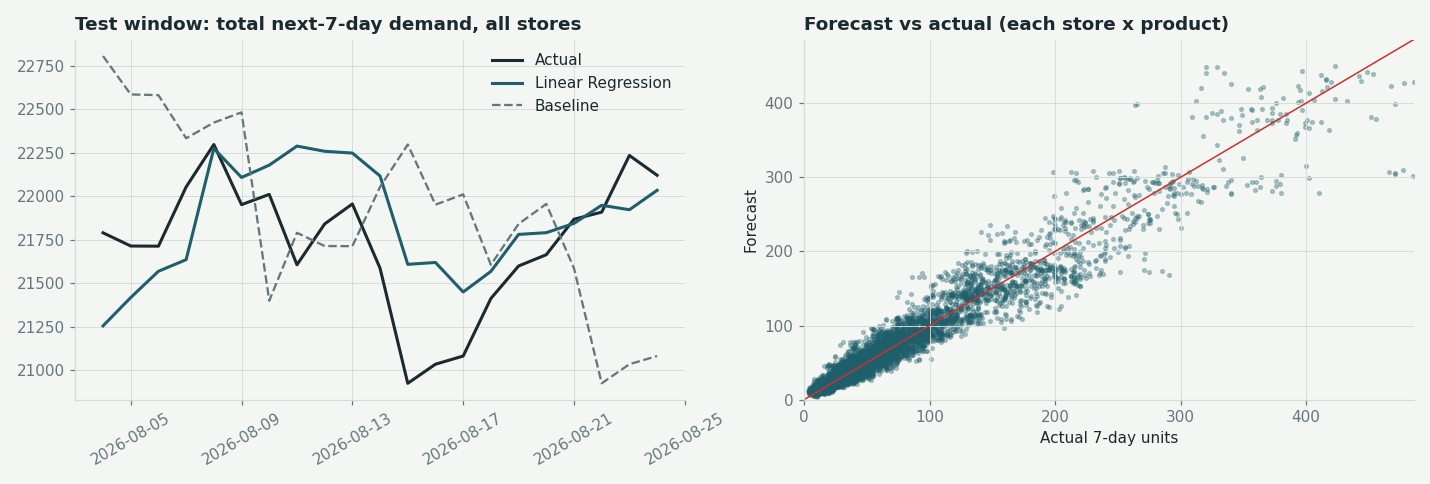

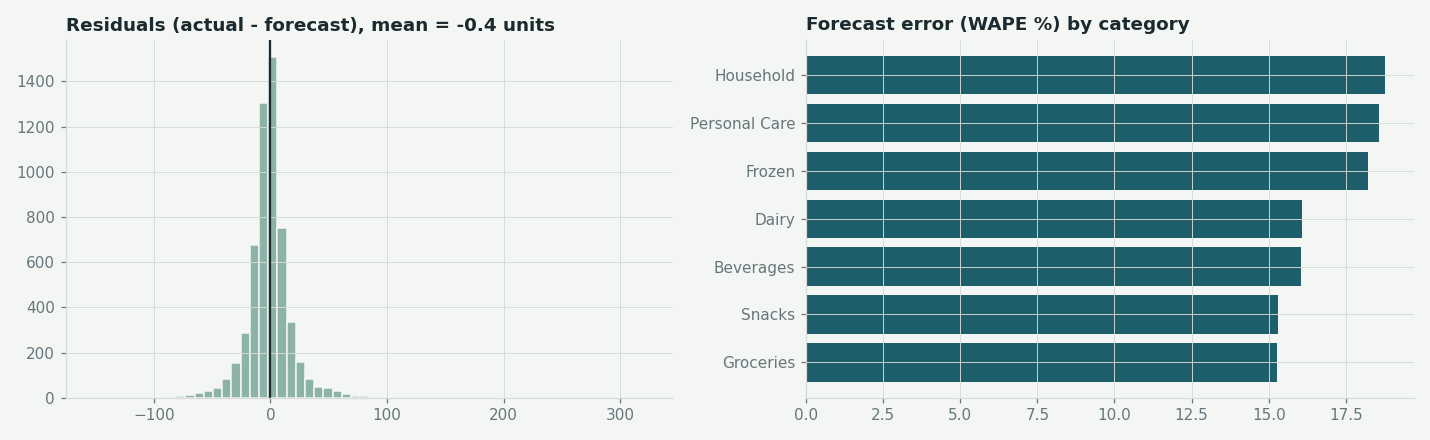

In [ ]:
display(Image(FIG / '08_forecast_vs_actual.png')); display(Image(FIG / '09_residuals.png'))

### Model 2: stock-out risk

In [ ]:
display(pd.DataFrame(meta['classification']['validation']).drop(columns='split').round(3))
c = meta['classification']
print('Selected:', c['selected'], '| threshold:', c['threshold'], '| XGBoost scale_pos_weight:', c['pos_weight'])
display(pd.DataFrame(c['test']).drop(columns='split').round(3))

,model,Accuracy,Precision,Recall,F1,F2,ROC_AUC,PR_AUC,fit_sec
0,Naive Bayes,0.716,0.471,0.510,0.490,0.502,0.740,0.490,0.068
1,Decision Tree,0.593,0.369,0.740,0.493,0.616,0.700,0.436,0.409
2,Random Forest,0.732,0.498,0.424,0.458,0.437,0.752,0.491,37.520
3,XGBoost,0.663,0.425,0.732,0.538,0.640,0.766,0.505,1.983
4,KNN,0.741,0.525,0.316,0.395,0.344,0.733,0.471,0.047
5,SVM (RBF),0.735,0.508,0.230,0.316,0.258,0.737,0.459,12.699


Selected: XGBoost | threshold: 0.33000000000000007 | XGBoost scale_pos_weight: 2.834


,model,Accuracy,Precision,Recall,F1,F2,ROC_AUC,PR_AUC,threshold
0,XGBoost (calibrated),0.751,0.524,0.604,0.561,0.586,0.796,0.546,0.33


**Class imbalance.** About 26% of windows are positive. The models use `class_weight='balanced'`
(trees and SVM) and `scale_pos_weight` (XGBoost), and are ranked by PR-AUC, which is more honest
than accuracy under imbalance.

**Calibration.** Weighting distorts probabilities, so the winner is isotonic-calibrated on the
validation weeks. That makes the brief's fixed bands (0.70 / 0.40) mean what they say.

**Threshold.** The binary alert threshold is chosen on validation to maximise F2 (recall weighted
double), subject to precision of at least 45% so managers keep trusting the alerts.

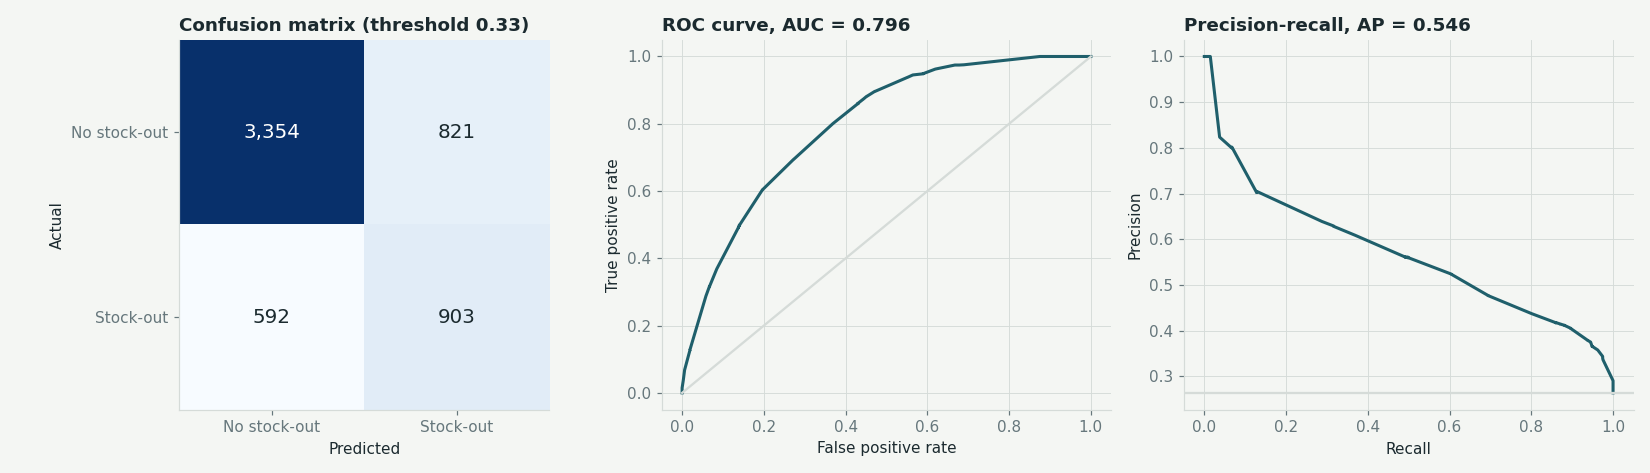

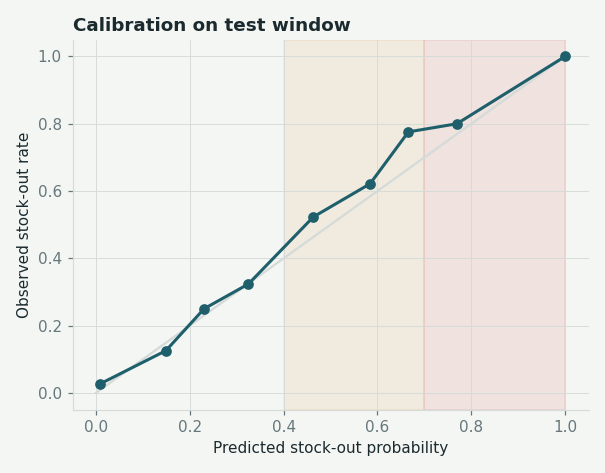

In [ ]:
display(Image(FIG / '10_classifier_evaluation.png')); display(Image(FIG / '11_calibration.png'))

## 4. Global explainability: permutation importance

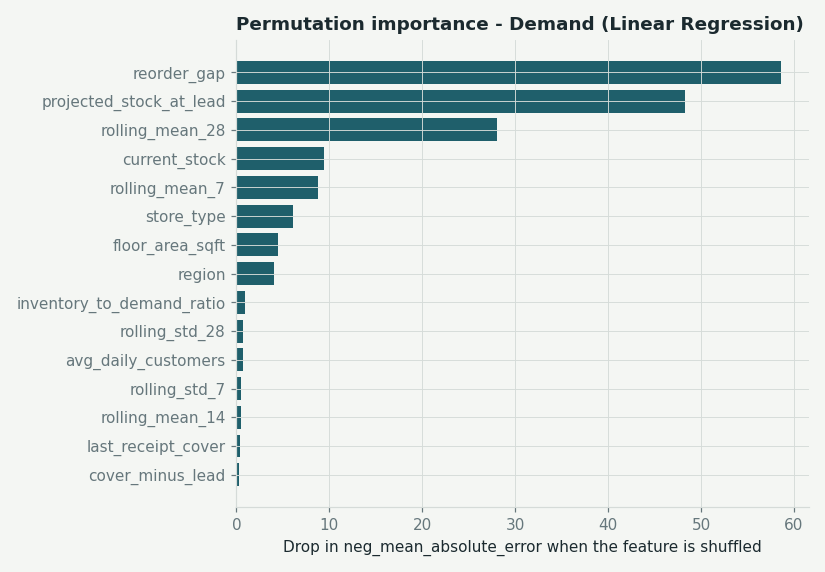

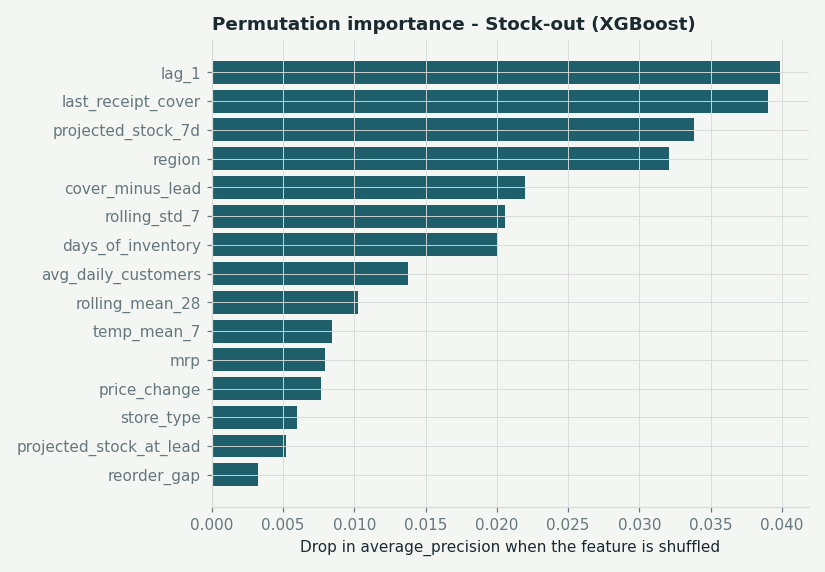

In [ ]:
display(Image(FIG / '12_importance_demand.png')); display(Image(FIG / '13_importance_stockout.png'))

Recent sales levels drive the demand forecast. Stock cover, delivery rhythm and recent stock-outs
drive risk. Both match how an experienced store manager thinks, which is a good sign the models
learned real structure rather than noise.